In [6]:
import matplotlib.pyplot as plt
import numpy as np
import stim
import tempfile
import os
import sinter

from honeycomb import CSSHoneycomb
from operations import Detector
from testing.codespace_distance import check_noiseless, effective_distance


from sims import run_experiment, build_circuit, check_circuit,estimate_logical_error_rate
from collections import defaultdict
import json

from phenom_honeycomb import build_phenomenological_circuit, PhenomenologicalHoneycomb, PhenomenologicalNoise 

The goal of this notebook is to generate results to compare to LiMagicStateInjection. We should hopefully have the tools we need to run sims and extract logical error rates.

An important thing to note is that we cannot compare with distance. We are instead going to compare with number of data qubits. This seems like a really logical comparison anyway in the context of implementing on real hardware, the number of data qubits is an important considertation.

# 1. Simulation and extracting error rates for phenomenological and circuit level models
I will collect the pipeline of computing error rates given an circuit and error model. We should use both the circuit-level and phenomenological models in the context of IBM and Microsoft.

## 1.1 Circuit-Level

In [12]:
CYCLE = ["bZ", "rX", "gZ", "bX"]
SHOTS = 100_000

base = json.load(open("error_model.json"))
p = 1e-3
model = {k: (float(p) if k.startswith("p_") else v) for k, v in base.items()}
json.dump(model, open("tmp_model.json", "w"))

circuit = build_circuit(cycle=CYCLE, error_model="tmp_model.json")
dets, obs = circuit.compile_detector_sampler(seed=1).sample(
    SHOTS, separate_observables=True
)

# Post-selection: keep only shots where no detector fired
accepted = ~dets.any(axis=1)
n_accepted = int(accepted.sum())
acceptance = n_accepted / SHOTS

# Logical errors among accepted shots only
# obs has shape (SHOTS, num_observables); a shot is a logical failure
# if any observable flipped
obs_accepted = obs[accepted]
logical_fail = obs_accepted.any(axis=1)
n_fail = int(logical_fail.sum())

if n_accepted > 0:
    logical_error_rate = n_fail / n_accepted

    # Binomial standard error (Wald); fine when n_fail is reasonably large
    stderr = np.sqrt(logical_error_rate * (1 - logical_error_rate) / n_accepted)

    # Wilson 95% interval - better behaved when n_fail is small or zero
    z = 1.96
    phat = logical_error_rate
    denom = 1 + z**2 / n_accepted
    centre = (phat + z**2 / (2 * n_accepted)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n_accepted + z**2 / (4 * n_accepted**2)) / denom
    ci_low, ci_high = centre - half, centre + half
else:
    logical_error_rate = float("nan")
    stderr = float("nan")
    ci_low = ci_high = float("nan")

print(f"Shots:                 {SHOTS}")
print(f"Accepted shots:        {n_accepted}")
print(f"Post-selection rate:   {acceptance:.6f}  (discard rate {1 - acceptance:.6f})")
print(f"Logical failures:      {n_fail}")
print(f"Logical error rate:    {logical_error_rate:.3e} ± {stderr:.1e}")
print(f"  95% Wilson interval: [{ci_low:.3e}, {ci_high:.3e}]")

Shots:                 100000
Accepted shots:        73250
Post-selection rate:   0.732500  (discard rate 0.267500)
Logical failures:      634
Logical error rate:    8.655e-03 ± 3.4e-04
  95% Wilson interval: [8.010e-03, 9.352e-03]


# 1.2 Phenomenological

In [8]:
CYCLE = ["bZ", "rX", "gZ", "bX"]
NOISE = PhenomenologicalNoise(p_data=1e-3, p_meas=1e-3)
SHOTS = 100_000


circuit = build_phenomenological_circuit(CYCLE, NOISE)
dets, obs = circuit.compile_detector_sampler(seed=1).sample(
    SHOTS, separate_observables=True
)

# Post-selection: keep only shots where no detector fired
accepted = ~dets.any(axis=1)
n_accepted = int(accepted.sum())
acceptance = n_accepted / SHOTS

# Logical errors among accepted shots only
# obs has shape (SHOTS, num_observables); a shot is a logical failure
# if any observable flipped
obs_accepted = obs[accepted]
logical_fail = obs_accepted.any(axis=1)
n_fail = int(logical_fail.sum())

if n_accepted > 0:
    logical_error_rate = n_fail / n_accepted

    # Binomial standard error (Wald); fine when n_fail is reasonably large
    stderr = np.sqrt(logical_error_rate * (1 - logical_error_rate) / n_accepted)

    # Wilson 95% interval - better behaved when n_fail is small or zero
    z = 1.96
    phat = logical_error_rate
    denom = 1 + z**2 / n_accepted
    centre = (phat + z**2 / (2 * n_accepted)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n_accepted + z**2 / (4 * n_accepted**2)) / denom
    ci_low, ci_high = centre - half, centre + half
else:
    logical_error_rate = float("nan")
    stderr = float("nan")
    ci_low = ci_high = float("nan")

print(f"Shots:                 {SHOTS}")
print(f"Accepted shots:        {n_accepted}")
print(f"Post-selection rate:   {acceptance:.6f}  (discard rate {1 - acceptance:.6f})")
print(f"Logical failures:      {n_fail}")
print(f"Logical error rate:    {logical_error_rate:.3e} ± {stderr:.1e}")
print(f"  95% Wilson interval: [{ci_low:.3e}, {ci_high:.3e}]")

Shots:                 100000
Accepted shots:        91925
Post-selection rate:   0.919250  (discard rate 0.080750)
Logical failures:      385
Logical error rate:    4.188e-03 ± 2.1e-04
  95% Wilson interval: [3.791e-03, 4.627e-03]


# 2. Running an experiment by incrementing error rates


[5x4] shape=(5, 4) config/5x4.json
  p2=0.05%  acc=0.955  fails=401/477389  LER=0.0840%
  p2=0.10%  acc=0.911  fails=440/273241  LER=0.1610%
  p2=0.15%  acc=0.869  fails=436/173886  LER=0.2507%
  p2=0.20%  acc=0.831  fails=576/166124  LER=0.3467%
  p2=0.25%  acc=0.793  fails=674/158549  LER=0.4251%
  p2=0.30%  acc=0.754  fails=793/150837  LER=0.5257%
  p2=0.35%  acc=0.722  fails=473/72182  LER=0.6553%
  p2=0.40%  acc=0.690  fails=501/68951  LER=0.7266%
  p2=0.45%  acc=0.659  fails=546/65852  LER=0.8291%
  p2=0.50%  acc=0.626  fails=579/62623  LER=0.9246%

[7x5] shape=(7, 5) config/7x5.json
  p2=0.05%  acc=0.917  fails=475/550167  LER=0.0863%
  p2=0.10%  acc=0.840  fails=417/252093  LER=0.1654%
  p2=0.15%  acc=0.769  fails=403/153882  LER=0.2619%
  p2=0.20%  acc=0.707  fails=508/141453  LER=0.3591%
  p2=0.25%  acc=0.648  fails=559/129613  LER=0.4313%
  p2=0.30%  acc=0.595  fails=573/118950  LER=0.4817%
  p2=0.35%  acc=0.545  fails=609/108919  LER=0.5591%
  p2=0.40%  acc=0.500  fails=68

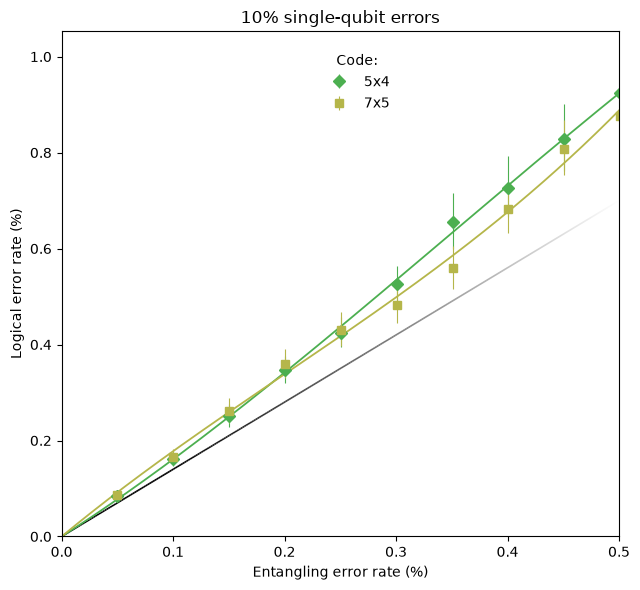

In [14]:
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba

# ============================ USER SETTINGS ============================
CONFIGS = {
    (5, 4):   "config/5x4.json",        # keys are ignored; only the paths are used
    (7, 5):   "config/7x5.json",
}
ERROR_MODEL = "error_model.json"
XMAX = 0.5
P2_PERCENT = np.linspace(0.05, XMAX + 0.001, 10)   # entangling (p_cnot) error rate, %
SINGLE_QUBIT_RATIO = 0.10                    # every other p_* = 0.10 * p2
TWO_QUBIT_KEYS = {"p_cnot"}
BATCH, MAX_SHOTS, TARGET_FAILS = 100_000, 5_000_000, 400

# (function of p2 in %, legend label, line style kwargs)
REFERENCE_LINES = [
    # (lambda p: p,         r"$p_L = p_2$",    dict(color="k", lw=1.2)),
    (lambda p: (7 / 5) * p, r"$p_L = 7/5 p$", dict(color="k", lw=1.2)),
]

# =======================================================================

base = json.load(open(ERROR_MODEL))
p_keys = [k for k in base if k.startswith("p_")]


def label_of(path):
    """First 3 characters of the path after 'config/'."""
    return path.split("config/", 1)[1][:3]


def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    ph = k / n
    d = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / d
    h = z * np.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / d
    return max(c - h, 0.0), min(c + h, 1.0)


def run_point(shape, config_path, p2, seed):
    p1 = SINGLE_QUBIT_RATIO * p2
    model = {k: ((p2 if k in TWO_QUBIT_KEYS else p1) if k in p_keys else v)
             for k, v in base.items()}
    with tempfile.NamedTemporaryFile("w", suffix=".json", delete=False) as f:
        json.dump(model, f)
        model_path = f.name
    try:
        circuit = build_circuit(cycle=CYCLE, ncols=shape[0], nrows=shape[1], config_filepath=config_path, error_model=model_path)
    finally:
        os.remove(model_path)

    sampler = circuit.compile_detector_sampler(seed=seed)
    shots = n_acc = n_fail = 0
    while shots < MAX_SHOTS and n_fail < TARGET_FAILS:
        dets, obs = sampler.sample(BATCH, separate_observables=True)
        acc = ~dets.any(axis=1)
        n_acc += int(acc.sum())
        n_fail += int(obs[acc].any(axis=1).sum())
        shots += BATCH

    ler = n_fail / n_acc if n_acc else np.nan
    lo, hi = wilson(n_fail, n_acc)
    return dict(p2=p2, shots=shots, n_acc=n_acc, n_fail=n_fail,
                acc=n_acc / shots, ler=ler, lo=lo, hi=hi)


# ------------------------------ sweep ------------------------------
results = {}   # label -> list of rows
for ci, (shape, path) in enumerate(CONFIGS.items()):
    lab = label_of(path)
    print(f"\n[{lab}] shape={shape} {path}")
    rows = []
    for pi, p2_pct in enumerate(P2_PERCENT):
        r = run_point(shape=shape, config_path=path, p2=p2_pct / 100,
                      seed=10_000 * ci + pi)
        rows.append(r)
        print(f"  p2={p2_pct:.2f}%  acc={r['acc']:.3f}  "
              f"fails={r['n_fail']}/{r['n_acc']}  LER={100 * r['ler']:.4f}%")
    results[lab] = rows

json.dump(results, open("li_sweep_results.json", "w"), indent=1, default=float)

# ------------------------------ plot ------------------------------
PALETTE = ["#4CAF50", "#B5B64A", "#4B3FA0", "#1A237E", "#E8432A", "#00897B", "#8E24AA", "#F9A825"]
MARKERS = ["D", "s", "o", "v", "^", "P", "X", "h"]
style = {k: (PALETTE[i % 8], MARKERS[i % 8]) for i, k in enumerate(results)}


def smooth_curve(x, y, xmax, deg=3):
    """Polynomial fit forced through the origin."""
    A = np.vstack([x**k for k in range(1, deg + 1)]).T
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    xs = np.linspace(0, xmax, 300)
    return xs, np.vstack([xs**k for k in range(1, deg + 1)]).T @ coef


def fading_line(ax, x, y, color="k", lw=1.2, fade_from=0.1, fade_to=0.5,
                alpha_end=0.0, **kw):
    """Solid until x = fade_from, then linearly fades to alpha_end at x = fade_to."""
    pts = np.column_stack([x, y]).reshape(-1, 1, 2)
    segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
    xmid = 0.5 * (x[:-1] + x[1:])
    t = np.clip((xmid - fade_from) / (fade_to - fade_from), 0, 1)
    alphas = 1 - t * (1 - alpha_end)
    colors = [to_rgba(color, a) for a in alphas]
    lc = LineCollection(segs, colors=colors, linewidths=lw, **kw)
    ax.add_collection(lc)
    return lc


def draw(ax, xmax, ms, show_err=True, fade=True):
    # reference lines
    xs_ref = np.linspace(0, xmax, 300)
    for f, lab_ref, kw in REFERENCE_LINES:
        if fade:
            fading_line(ax, xs_ref, f(xs_ref), color=kw.get("color", "k"),
                        lw=kw.get("lw", 1.2), fade_from=0.1, fade_to=0.5)
        else:
            ax.plot(xs_ref, f(xs_ref), **kw)

    # data
    for lab, rows in results.items():
        col, mk = style[lab]
        x = np.array([100 * r["p2"] for r in rows])
        y = np.array([100 * r["ler"] for r in rows])
        lo = np.array([100 * r["lo"] for r in rows])
        hi = np.array([100 * r["hi"] for r in rows])
        ok = np.isfinite(y)
        xs, ys = smooth_curve(x[ok], y[ok], x.max())
        ax.plot(xs, ys, color=col, lw=1.3)
        if show_err:
            ax.errorbar(x[ok], y[ok], yerr=[(y - lo)[ok], (hi - y)[ok]], fmt=mk,
                        color=col, ms=ms, elinewidth=0.8, label=lab)
        else:
            ax.plot(x[ok], y[ok], mk, color=col, ms=ms)


fig, ax = plt.subplots(figsize=(6.5, 6))
draw(ax, 0.5, ms=6, show_err=True)
ymax = 100 * np.nanmax([r["hi"] for rows in results.values() for r in rows])
ax.set_xlim(0, XMAX)
ax.set_ylim(0, 1.05 * ymax)
ax.set_xlabel("Entangling error rate (%)")
ax.set_ylabel("Logical error rate (%)")
ax.set_title(f"{int(SINGLE_QUBIT_RATIO * 100)}% single-qubit errors")
ax.legend(title="Code:", frameon=False, loc="upper left", bbox_to_anchor=(0.45, 0.98))

plt.tight_layout()
plt.savefig("li_fig_a.png", dpi=250)
plt.show()

In [16]:
import itertools
from collections import defaultdict
import numpy as np
import stim


def dem_mechanisms(circuit: stim.Circuit):
    """Return list of (p, frozenset(detectors), frozenset(observables))."""
    dem = circuit.detector_error_model(
        decompose_errors=False,          # we want raw mechanisms, not graph-like edges
        approximate_disjoint_errors=True,  # tolerate DEPOLARIZE-style correlated channels
        ignore_decomposition_failures=True,
    )
    mechs = []
    for inst in dem.flattened():
        if inst.type != "error":
            continue
        p = inst.args_copy()[0]
        dets, obs = set(), set()
        for t in inst.targets_copy():
            if t.is_relative_detector_id():
                dets ^= {t.val}
            elif t.is_logical_observable_id():
                obs ^= {t.val}
        mechs.append((p, frozenset(dets), frozenset(obs)))
    return mechs


def perturbative_postselected_rate(circuit: stim.Circuit, p_ref: float):
    """
    Perturbative estimate of the post-selected logical error rate.
    Returns coefficients such that, with p = p_cnot:

        p_L(p) ≈ A p + C p^2        (A = first-order, C = second-order)
        P_acc(p) ≈ 1 - a1 p

    p_ref is the p_cnot value the circuit was built with.
    """
    mechs = dem_mechanisms(circuit)

    # ---- first order ----
    S_fail1 = sum(p for p, D, O in mechs if not D and O)   # undetected logical faults
    S_det1 = sum(p for p, D, O in mechs if D)              # detected faults (rejected)

    # ---- second order: pairs that cancel in detectors but flip an observable ----
    # Group by detector set; the pair (i,j) is undetected iff D_i == D_j.
    # Also include pairs where one of them is already an undetected-logical (D empty) -> that's
    # first order already, so skip pairs involving D-empty mechs.
    groups = defaultdict(list)
    for p, D, O in mechs:
        if D:
            groups[D].append((p, O))
    S_fail2 = 0.0
    for D, lst in groups.items():
        for (pi, Oi), (pj, Oj) in itertools.combinations(lst, 2):
            if Oi ^ Oj:                      # net logical flip
                S_fail2 += pi * pj

    # Convert to coefficients in p_cnot (all mechanism probs are ∝ p_cnot at leading order)
    A = S_fail1 / p_ref
    a1 = S_det1 / p_ref
    B = S_fail2 / p_ref**2
    # p_L = P(fail & accept)/P(accept) ≈ (A p + B p^2)/(1 - a1 p) ≈ A p + (B + A a1) p^2
    C = B + A * a1
    return dict(A=A, a1=a1, B=B, C=C, n_mechs=len(mechs))


def predict(coef, p):
    acc = 1 - coef["a1"] * p
    pL = coef["A"] * p + coef["C"] * p**2
    return acc, pL


def explain_undetected_logicals(circuit: stim.Circuit, max_items=10):
    """Show which circuit locations cause undetectable logical faults (the first-order culprits)."""
    dem = circuit.detector_error_model(decompose_errors=False,
                                       approximate_disjoint_errors=True,
                                       ignore_decomposition_failures=True)
    bad = stim.DetectorErrorModel()
    for inst in dem.flattened():
        if inst.type == "error":
            has_det = any(t.is_relative_detector_id() for t in inst.targets_copy())
            has_obs = any(t.is_logical_observable_id() for t in inst.targets_copy())
            if has_obs and not has_det:
                bad.append(inst)
    if len(bad) == 0:
        print("No single fault is both undetected and logical -> first-order term is 0.")
        return
    for e in circuit.explain_detector_error_model_errors(
            dem_filter=bad, reduce_to_one_representative_error=True)[:max_items]:
        print(e)


# ------------------------------------------------------------------ usage
if __name__ == "__main__":
    CYCLE = ["bZ", "rX", "gZ", "bX"]
    SHOTS = 100_000

    def build(p_cnot):
        p_other = p_cnot / 10
        # adapt to your builder: everything except the CNOT/two-qubit noise uses p_other
        noise = PhenomenologicalNoise(p_data=p_other, p_meas=p_other)
        return build_phenomenological_circuit(CYCLE, noise)

    p_ref = 1e-3
    circuit = build(p_ref)
    coef = perturbative_postselected_rate(circuit, p_ref)
    print(coef)
    print(f"p_L(p) ≈ {coef['A']:.4g}·p + {coef['C']:.4g}·p²")
    print(f"P_acc(p) ≈ 1 - {coef['a1']:.4g}·p")

    explain_undetected_logicals(circuit)

    # ---- sanity check against Monte Carlo + linearity check across p ----
    for p in [3e-4, 1e-3, 3e-3]:
        c = build(p)
        dets, obs = c.compile_detector_sampler(seed=1).sample(SHOTS, separate_observables=True)
        acc = ~dets.any(axis=1)
        mc = obs[acc].any(axis=1).mean() if acc.any() else float("nan")
        acc_pred, pL_pred = predict(coef, p)
        print(f"p={p:.0e}  MC p_L={mc:.3e}  pert p_L={pL_pred:.3e}  "
              f"MC acc={acc.mean():.4f}  pert acc={acc_pred:.4f}")

{'A': 0.39994778148145543, 'a1': 8.464711544743203, 'B': 0.7063000403849793, 'C': 4.091742643585487, 'n_mechs': 52}
p_L(p) ≈ 0.3999·p + 4.092·p²
P_acc(p) ≈ 1 - 8.465·p
ExplainedError {
    dem_error_terms: L0
    CircuitErrorLocation {
        flipped_pauli_product: X8[coords 2,1]
        Circuit location stack trace:
            (after 0 TICKs)
            at instruction #22 (DEPOLARIZE1) in the circuit
            at target #1 of the instruction
            resolving to DEPOLARIZE1(0.0001) 8[coords 2,1]
    }
}
ExplainedError {
    dem_error_terms: L0 L1
    CircuitErrorLocation {
        flipped_pauli_product: Y8[coords 2,1]
        Circuit location stack trace:
            (after 2 TICKs)
            at instruction #27 (DEPOLARIZE1) in the circuit
            at target #8 of the instruction
            resolving to DEPOLARIZE1(0.0001) 8[coords 2,1]
    }
}
ExplainedError {
    dem_error_terms: L1
    CircuitErrorLocation {
        flipped_pauli_product: Z9[coords 3,1]
        Circu

In [ ]:
import json, os, tempfile
import numpy as np

CYCLE = ["bZ", "rX", "gZ", "bX"]
SHOTS = 100_000

base = json.load(open("error_model.json"))
p_keys = [k for k in base if k.startswith("p_")]
print("Noise keys found:", {k: base[k] for k in p_keys})

# Which key(s) are the CNOT rate? Edit this list if the auto-detection guesses wrong.
CNOT_KEYS = [k for k in p_keys if any(s in k.lower() for s in ("cnot", "cx", "2q", "two"))]
if not CNOT_KEYS:
    raise ValueError(f"Couldn't identify the CNOT key among {p_keys}; set CNOT_KEYS by hand.")
print("Treating as p_cnot:", CNOT_KEYS, "| everything else = p_cnot / 10")

_tmp = os.path.join(tempfile.mkdtemp(), "model.json")

def build(p_cnot):
    model = {
        k: ((p_cnot if k in CNOT_KEYS else p_cnot / 10) if k.startswith("p_") else v)
        for k, v in base.items()
    }
    json.dump(model, open(_tmp, "w"))
    return build_circuit(cycle=CYCLE, error_model=_tmp)


def per_observable_first_order(circuit, p_ref):
    """First-order undetected-logical coefficient, split by which observables flip."""
    out = {}
    for p, D, O in dem_mechanisms(circuit):
        if not D and O:
            out[tuple(sorted(O))] = out.get(tuple(sorted(O)), 0.0) + p / p_ref
    return out


p_ref = 1e-3
circuit = build(p_ref)
coef = perturbative_postselected_rate(circuit, p_ref)
print(coef)
print(f"p_L(p)  ≈ {coef['A']:.4g}·p + {coef['C']:.4g}·p²")
print(f"P_acc(p) ≈ 1 - {coef['a1']:.4g}·p")
print("First-order coefficient by observable set:", per_observable_first_order(circuit, p_ref))

explain_undetected_logicals(circuit)

# Sanity check vs Monte Carlo across p (including the p that matches your original run)
for p in [3e-4, 1e-3, 3e-3]:
    c = build(p)
    dets, obs = c.compile_detector_sampler(seed=1).sample(SHOTS, separate_observables=True)
    acc = ~dets.any(axis=1)
    n_acc = int(acc.sum())
    n_fail = int(obs[acc].any(axis=1).sum())
    mc = n_fail / n_acc if n_acc else float("nan")
    acc_pred, pL_pred = predict(coef, p)
    print(f"p={p:.0e}  MC p_L={mc:.3e} ({n_fail} fails)  pert p_L={pL_pred:.3e}  "
          f"MC acc={acc.mean():.4f}  pert acc={acc_pred:.4f}")